In [ ]:
import json

import geopandas as gpd
import matplotlib.pyplot as plt
import momepy as mp
import networkx as nx
import numpy as np
import pandas as pd

In [79]:
# TODO instead of doing full gini each time, compute to what borough(s) each edge is in and update the value whenever an edge is added
# Should be much faster, which allows to compute for all orders

In [2]:
def compute_gini(gdf_edges, gdf_arr):
    """Compute the Gini coefficient of distribution of edges on polygons, normalized by their area."""
    gdf_sjoin = gdf_arr.sjoin(gdf_edges)
    gdf_sjoin["eff_length"] = gdf_sjoin["length"] / gdf_sjoin["index_right"].map(
        gdf_sjoin["index_right"].value_counts()
    )
    gdf_sjoin = gdf_sjoin.dissolve(by="arrondissement", aggfunc={"eff_length": "sum"})
    arr_vals = gdf_sjoin["eff_length"] / gdf_sjoin.geometry.area
    return gini(arr_vals)


# Function from https://github.com/oliviaguest/gini
def gini(array):
    """Calculate the Gini coefficient of a numpy array."""
    array = np.sort(array)  # values must be sorted
    index = np.arange(1, array.shape[0] + 1)  # index per array element
    n = array.shape[0]  # number of array elements
    return (np.sum((2 * index - n - 1) * array)) / (
        n * np.sum(array)
    )  # Gini coefficient


def init_gdf(gdf_edges, end_folder):
    gdf = gdf_edges.copy()
    if end_folder == "2021":
        gdf["built"] = gdf["built_in"].apply(lambda x: 1 if x == "2021-01-01" else 0)
    elif end_folder == "2026":
        gdf["built"] = gdf["built_in"].apply(lambda x: 1 if x != "No" else 0)
    elif end_folder == "Nothing":
        G = mp.gdf_to_nx(gdf, integer_labels=False, preserve_index=True)
        closeness = nx.closeness_centrality(G, distance="length")
        edge_closeness = {
            edge: (closeness[edge[0]] + closeness[edge[1]]) / 2
            for edge in G.edges
            if (
                (G.edges[edge]["highway"] == "primary")
                & (G.edges[edge]["level"] == "primary")
                & (G.edges[edge]["built_in"] == "2021-01-01")
            )
        }
        choice = max(edge_closeness, key=edge_closeness.get)
        gdf["built"] = gdf.apply(
            lambda df: (
                1
                if (
                    ((df["from"] == str(choice[0])) & (df["to"] == str(choice[1])))
                    or ((df["to"] == str(choice[0])) & (df["from"] == str(choice[1])))
                )
                else 0
            ),
            axis=1,
        )
    return gdf

In [3]:
gdf_bikenet = gpd.read_file("../data/processed/bikenet_edges.gpkg")

In [4]:
gdf_arr = gpd.read_file("../data/processed/paris_arr_pop.gpkg")
gdf_arr_buff = gdf_arr.to_crs(gdf_bikenet.crs)
gdf_arr_buff.geometry = gdf_arr_buff.buffer(50)

In [5]:
gdf_sjoin = gdf_arr_buff.sjoin(gdf_bikenet)
gdf_sjoin["eff_length"] = gdf_sjoin["length"] / gdf_sjoin["index_right"].map(
    gdf_sjoin["index_right"].value_counts()
)
gdf_sjoin = gdf_sjoin.dissolve(
    by="arrondissement", aggfunc={"eff_length": "sum", "area": "first"}
)
gdf_sjoin["lanes_per_kms"] = (gdf_sjoin["eff_length"] / 10**3) / gdf_sjoin["area"]

<Axes: >

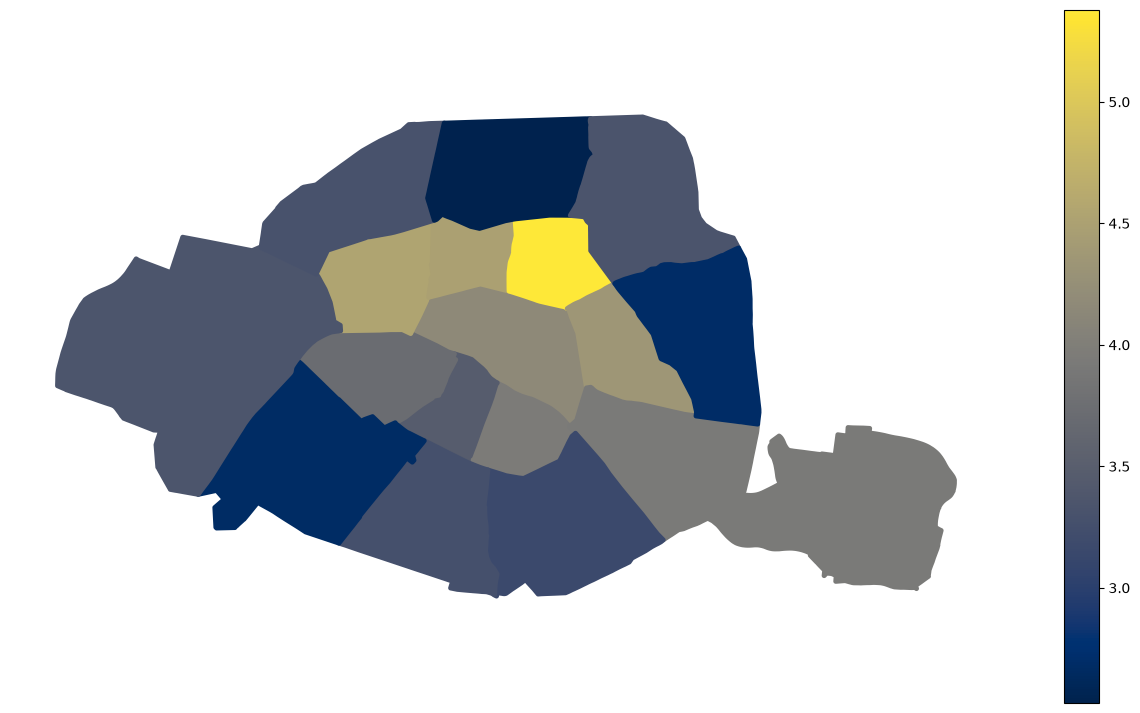

In [6]:
fig, ax = plt.subplots(figsize=(16, 9))
ax.set_axis_off()
gdf_sjoin.plot(ax=ax, column="lanes_per_kms", legend=True, cmap="cividis")

Text(0, 0.5, 'Lane kilometer per kilometer square')

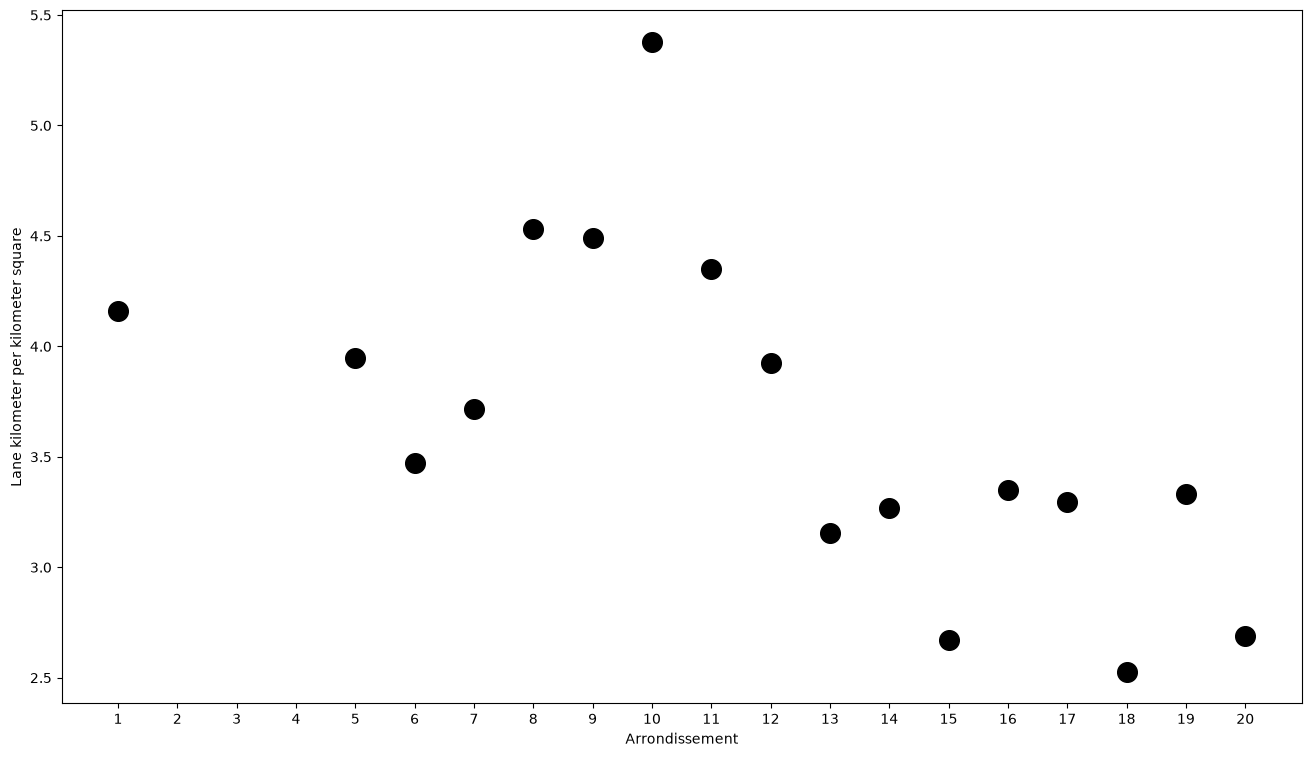

In [7]:
fig, ax = plt.subplots(figsize=(16, 9))
ax.set_xticks(range(1, 21))
ax.scatter(gdf_sjoin.index, gdf_sjoin["lanes_per_kms"], color="black", s=200)
ax.set_xlabel("Arrondissement")
ax.set_ylabel("Lane kilometer per kilometer square")

In [8]:
gdf_sjoin["rep"] = gdf_sjoin.geometry.centroid

<Axes: >

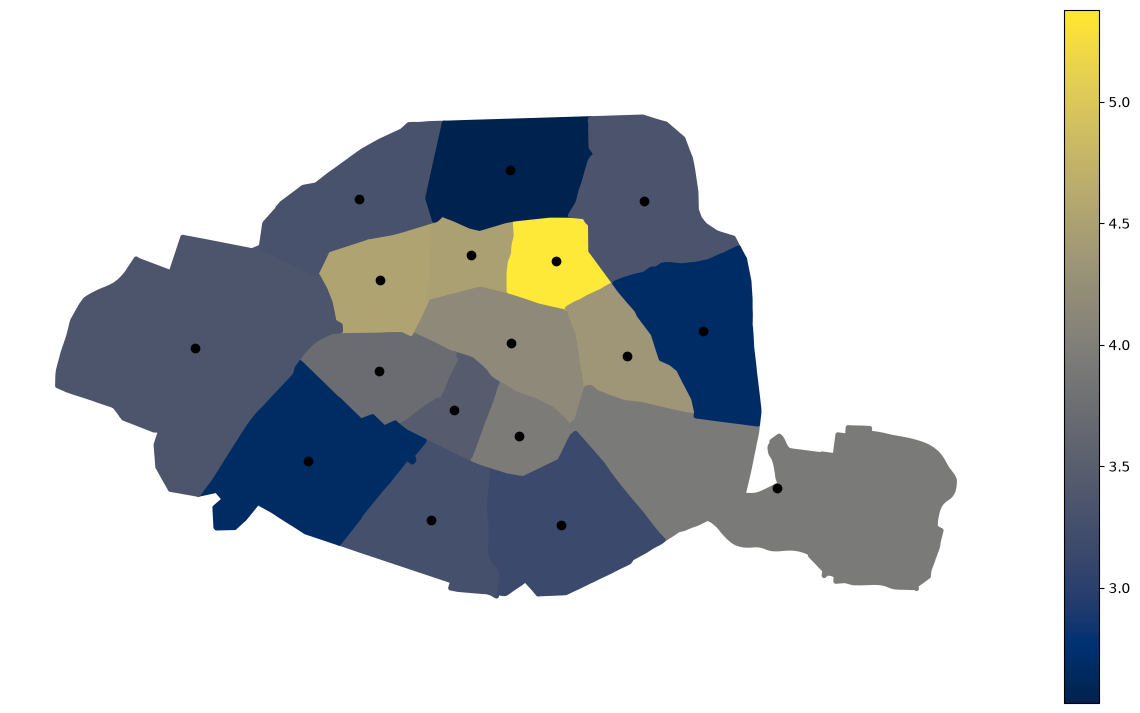

In [9]:
fig, ax = plt.subplots(figsize=(16, 9))
ax.set_axis_off()
gdf_sjoin.plot(ax=ax, column="lanes_per_kms", legend=True, cmap="cividis")
gdf_sjoin["rep"].plot(ax=ax, color="black")

In [10]:
gdf_sjoin["dist_to_center"] = gdf_sjoin["rep"].distance(gdf_sjoin.loc[1, "rep"]) / 10**3

Text(0, 0.5, 'Lane kilometer per kilometer square')

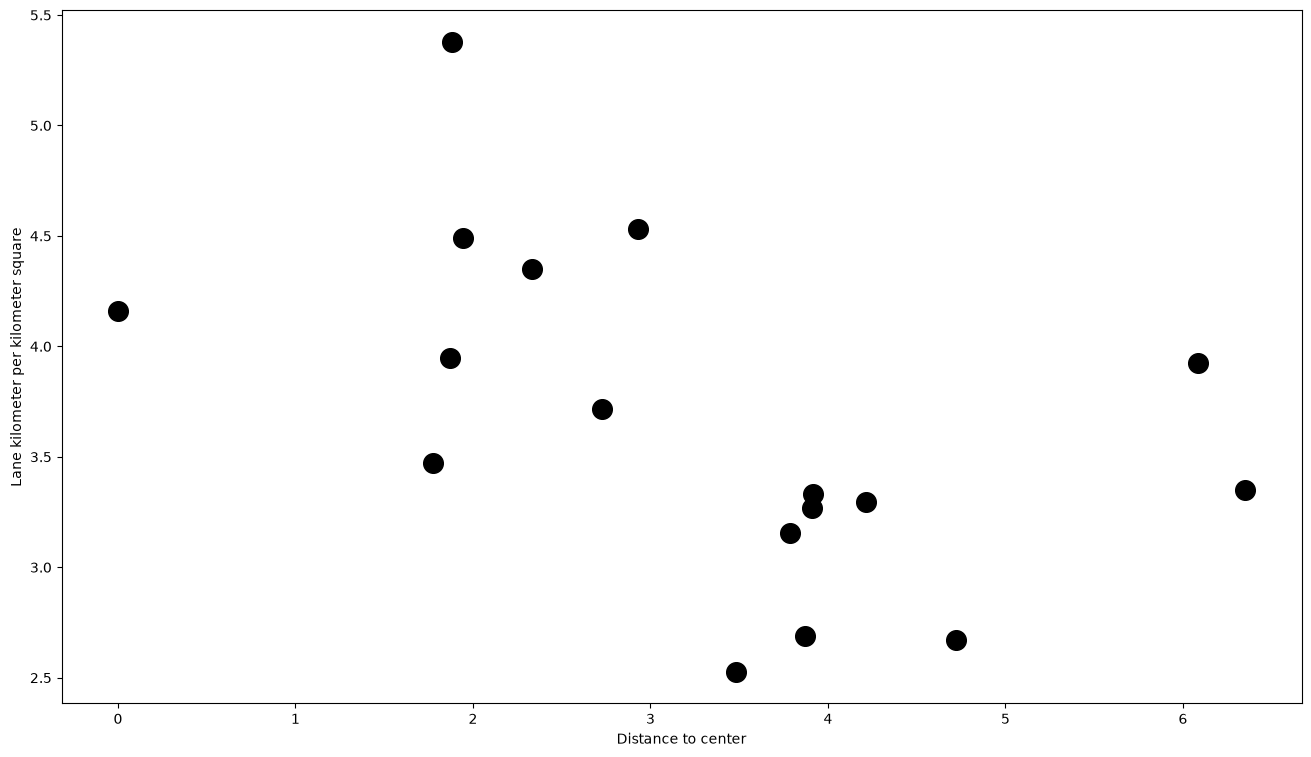

In [11]:
fig, ax = plt.subplots(figsize=(16, 9))
ax.scatter(
    gdf_sjoin["dist_to_center"], gdf_sjoin["lanes_per_kms"], color="black", s=200
)
ax.set_xlabel("Distance to center")
ax.set_ylabel("Lane kilometer per kilometer square")

In [12]:
TIMESTAMPS = [
    "2021-01-01",
    "2023-05-17",
    "2023-10-01",
    "2024-01-15",
    "2024-04-04",
    "2024-08-22",
    "2024-12-22",
    "2025-06-02",
    "2026-01-28",
    "No",
]

In [13]:
real_ginis = []
for i in range(len(TIMESTAMPS)):
    gdf_edges = gdf_bikenet[gdf_bikenet["built_in"].isin(TIMESTAMPS[: i + 1])]
    real_ginis.append(compute_gini(gdf_edges, gdf_arr_buff))

In [14]:
real_met = pd.read_json("../data/processed/2021/bs_400_real/metrics_growth.json")

In [15]:
gdf_end = init_gdf(gdf_bikenet, "2021")

In [16]:
with open("../data/processed/2021/bs_400_dual_betweenness/" + "order_growth.json") as f:
    order_growth = json.load(f)

In [17]:
with open(
    "../data/processed/2021/bs_400_dual_betweenness/" + "metrics_growth.json"
) as f:
    met_dict = json.load(f)

In [30]:
gdf_end["from"] = gdf_end["from"].apply(
    lambda x: (float(x.split(",")[0][1:]), float(x.split(",")[1][1:-1]))
)

In [33]:
gdf_end["to"] = gdf_end["to"].apply(
    lambda x: (float(x.split(",")[0][1:]), float(x.split(",")[1][1:-1]))
)

In [34]:
gdf_end["key"] = gdf_end.apply(lambda df: (df["from"], df["to"], 0), axis=1)

In [36]:
order_growth = [(tuple(val[0]), tuple(val[1]), val[2]) for val in order_growth]

In [37]:
order_dict = {val: idx for idx, val in enumerate(order_growth)}

In [38]:
gdf_end["order"] = gdf_end["key"].map(order_dict)

In [40]:
order_growth_rev = [(tuple(val[1]), tuple(val[0]), val[2]) for val in order_growth]

In [41]:
order_dict_rev = {val: idx for idx, val in enumerate(order_growth_rev)}

In [44]:
gdf_end["order_rev"] = gdf_end["key"].map(order_dict_rev)

In [62]:
gdf_end["order_comb"] = gdf_end["order"].fillna(gdf_end["order_rev"])
gdf_end["order_comb"] = gdf_end["order_comb"].fillna(-1).map(int)
gdf_end = gdf_end.sort_values(by="order_comb")

In [76]:
len(range(max(gdf_end["order_comb"]) + 1))

389

In [ ]:
ginis_db = [compute_gini(gdf_end[gdf_end["order_comb"] == -1], gdf_arr_buff)]
for i in range(max(gdf_end["order_comb"]) + 1):
    gdf_edges_filt = gdf_end[gdf_end["order_comb"] <= i + 1]
    ginis_db.append(compute_gini(gdf_edges_filt, gdf_arr_buff))

In [69]:
len(ginis_db)

389

In [70]:
len(met_dict["xx"])

390

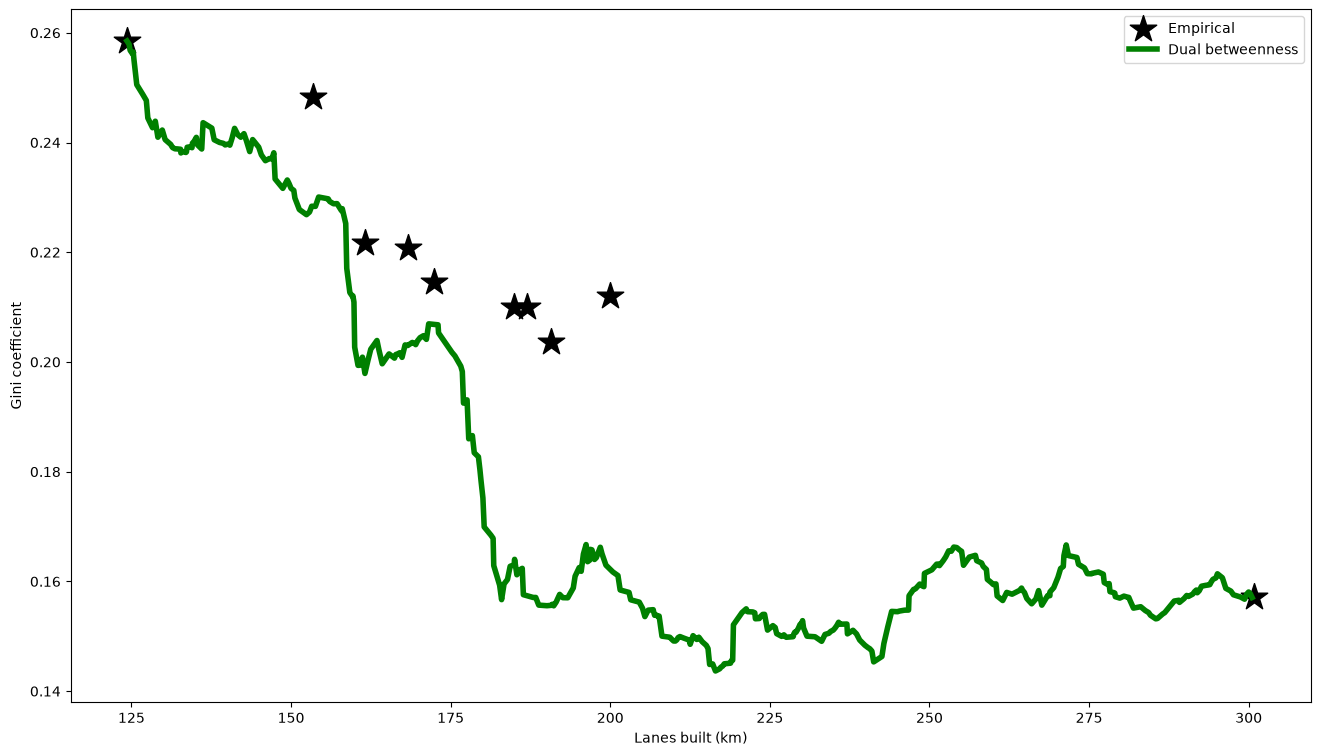

In [72]:
fig, ax = plt.subplots(figsize=(16, 9))
ax.scatter(
    real_met["xx"] / 10**3,
    real_ginis,
    color="black",
    marker="*",
    s=400,
    label="Empirical",
)
ax.plot(
    np.array(met_dict["xx"][:-1]) / 10**3,
    ginis_db,
    color="green",
    label="Dual betweenness",
    linewidth=4,
)
ax.set_ylabel("Gini coefficient")
ax.set_xlabel("Lanes built (km)")
ax.legend()